# 01 · Sentinel-2 before/after for one plot

**Goal:** visually and numerically compare a plot at the EUDR cut-off (dry season 2019/20) with today (dry season 2025/26), using only open data.

- Imagery: Sentinel-2 L2A from Element 84 Earth Search (AWS), no account needed
- Cloud mask: Scene Classification Layer (SCL)
- Composite: per-pixel median of all clear observations in the window
- Dry season (Nov–Mar) is used because south-west Côte d'Ivoire is very cloudy the rest of the year

⚠️ Demo plots are **synthetic**.

In [1]:
import json, sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import shape, box

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from eudr_screen import sentinel2 as s2

plots = gpd.read_file(ROOT / "data" / "demo_plots.geojson")
plots[["plot_id", "expected_case", "declared_area_ha", "geometry"]]

,plot_id,expected_case,declared_area_ha,geometry
0,DEMO-001,post2020_loss,2.50,POINT (-7.479 6.301)
1,DEMO-002,post2020_loss,6.25,"POLYGON ((-7.53612 5.43988, -7.53388 5.43988, ..."
2,DEMO-003,post2020_loss,2.50,POINT (-7.409 5.813)
3,DEMO-004,post2020_loss,6.25,"POLYGON ((-7.37412 5.55188, -7.37188 5.55188, ..."
4,DEMO-005,post2020_loss,2.50,POINT (-7.495 6.297)
5,DEMO-006,post2020_loss,6.25,"POLYGON ((-7.32012 5.45988, -7.31788 5.45988, ..."
6,DEMO-007,post2020_loss,2.50,POINT (-7.563 5.813)
7,DEMO-008,pre2020_loss,2.50,POINT (-6.641 5.961)
8,DEMO-009,pre2020_loss,6.25,"POLYGON ((-7.55412 6.15388, -7.55188 6.15388, ..."
9,DEMO-010,pre2020_loss,2.50,POINT (-6.833 5.843)


## Pick a plot
Points (< 4 ha) are buffered to a circle of the declared area so we have something to measure.

In [2]:
PLOT_ID = "DEMO-001"
BEFORE = ("2019-11-01", "2020-03-31")   # around the 31 Dec 2020 cut-off baseline
AFTER  = ("2025-11-01", "2026-03-31")   # latest complete dry season

row = plots.set_index("plot_id").loc[PLOT_ID]
geom = row.geometry
utm = gpd.GeoSeries([geom], crs=4326).estimate_utm_crs()
g_utm = gpd.GeoSeries([geom], crs=4326).to_crs(utm)
if geom.geom_type == "Point":
    r = np.sqrt(row.declared_area_ha * 10_000 / np.pi)
    g_utm = g_utm.buffer(r)
plot_utm = g_utm.iloc[0]

# context window: ~1.5 km around the plot
lon, lat = geom.centroid.x, geom.centroid.y
d = 0.007
bbox = (lon - d, lat - d, lon + d, lat + d)
print(row.expected_case, "| bbox", [round(v, 4) for v in bbox])

post2020_loss | bbox [-7.486, 6.294, -7.472, 6.308]


## Load and composite

In [3]:
comps = {}
for label, (a, b) in {"before": BEFORE, "after": AFTER}.items():
    items = s2.search(bbox, a, b, max_cloud=60)
    ds = s2.load_cube(items, bbox, crs=str(utm))
    comps[label] = s2.median_composite(ds).compute()
    print(f"{label}: {len(items)} scenes, median clear obs per pixel = {int(comps[label].clear_obs.median())}")

before: 47 scenes, median clear obs per pixel = 16


after: 28 scenes, median clear obs per pixel = 9


## Plot-level numbers

In [4]:
import rioxarray  # noqa: F401  (adds .rio)

def plot_mean_ndvi(comp):
    nd = s2.ndvi(comp).rio.write_crs(utm)
    return float(nd.rio.clip([plot_utm], drop=True).mean())

nd_before = plot_mean_ndvi(comps["before"])
nd_after = plot_mean_ndvi(comps["after"])
print(f"NDVI inside plot: before {nd_before:.2f} -> after {nd_after:.2f}  (change {nd_after - nd_before:+.2f})")

NDVI inside plot: before 0.56 -> after 0.30  (change -0.26)


## Maps
True colour before/after and NDVI change. Red = vegetation loss, the plot outline is drawn in yellow.

PosixPath('/Users/hazalyalcin/Upwork1/outputs/DEMO-001_before_after.png')

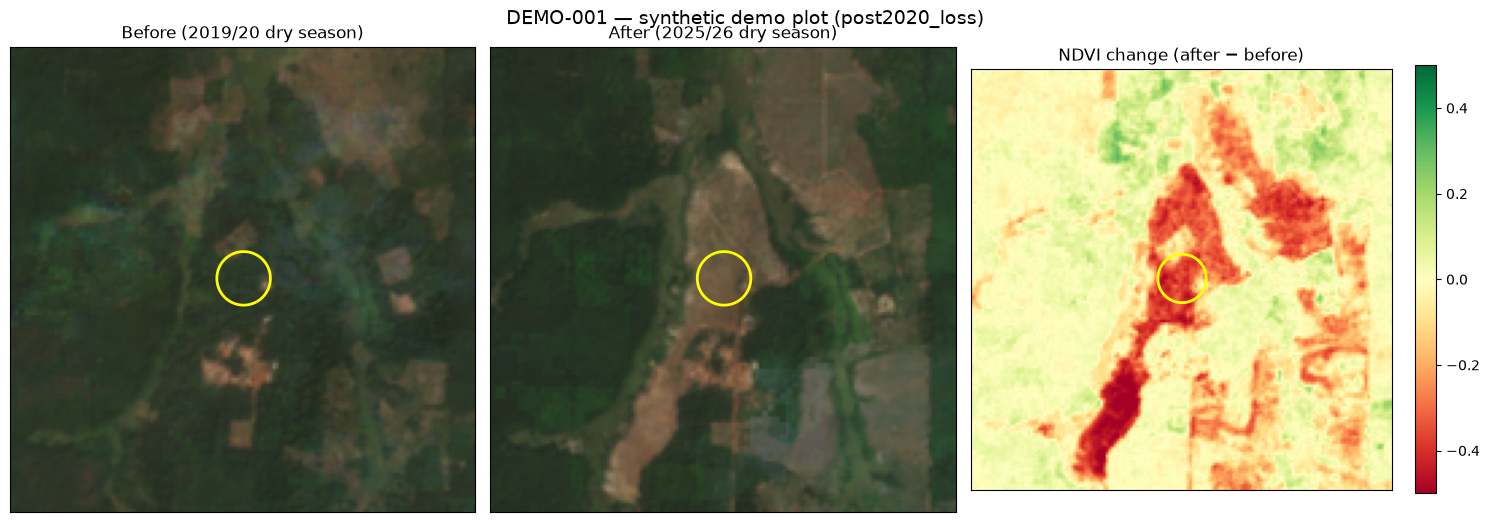

In [5]:
extent = lambda c: [float(c.x.min()), float(c.x.max()), float(c.y.min()), float(c.y.max())]
diff = s2.ndvi(comps["after"]) - s2.ndvi(comps["before"])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, img) in zip(axes, [("Before (2019/20 dry season)", s2.rgb(comps["before"])),
                                    ("After (2025/26 dry season)", s2.rgb(comps["after"]))]):
    ax.imshow(img, extent=extent(comps["before"]))
    ax.set_title(title)
im = axes[2].imshow(diff, cmap="RdYlGn", vmin=-0.5, vmax=0.5, extent=extent(comps["before"]))
axes[2].set_title("NDVI change (after − before)")
fig.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    gpd.GeoSeries([plot_utm]).boundary.plot(ax=ax, color="yellow", linewidth=2)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
fig.suptitle(f"{PLOT_ID} — synthetic demo plot ({row.expected_case})", y=1.04, fontsize=14)
out = ROOT / "outputs" / f"{PLOT_ID}_before_after.png"
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=120, bbox_inches="tight")
out

## What this does **not** tell us yet
- Whether the plot was **forest** at the cut-off (NDVI alone cannot separate forest from mature cocoa) → next notebook uses the JRC 2020 forest map and Hansen loss years.
- Median composites hide *when* within the period clearing happened.
- A drop in NDVI can also be harvest, drought or remaining cloud haze.